# 05. 변수 간 관계

변수끼리 얼마나 겹치는지(같은 역할 변수), 각 변수가 4주 뒤 가격 변화와 얼마나 관련 있는지, 소매가와 도매가가 같이 움직이는지. 모두 Spearman 순위상관.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parents[1]                     # demo/2_eda → 프로젝트 루트
P = ROOT / "data" / "processed"
NAMES = {"agri": "농산물", "livestock": "축산물", "fishery": "수산물"}
plt.rcParams.update({"font.family": "Malgun Gothic", "axes.unicode_minus": False, "figure.dpi": 110})
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:,.3f}".format)

In [2]:
# 전국 소매가 + 모든 변수 (원본 값): data/processed/{분야}/dataset.parquet
# 예측 대상은 소매가 → 소매 시계열만. 중도매가는 피처(whsl_price_kg 등 열)로만 쓰임
ds = {d: pd.read_parquet(P / d / "dataset.parquet", filters=[("se_nm", "==", "소매")]) for d in NAMES}
ds = {d: df[df.date >= "2016-01-01"] for d, df in ds.items()}     # 2015년은 이력 계산용 준비 기간
{NAMES[d]: df.shape for d, df in ds.items()}

{'농산물': (284054, 116), '축산물': (62275, 111), '수산물': (66874, 136)}

## 1. 날짜 단위 공통 변수끼리 상관 (기상·경제, 날짜 1행)

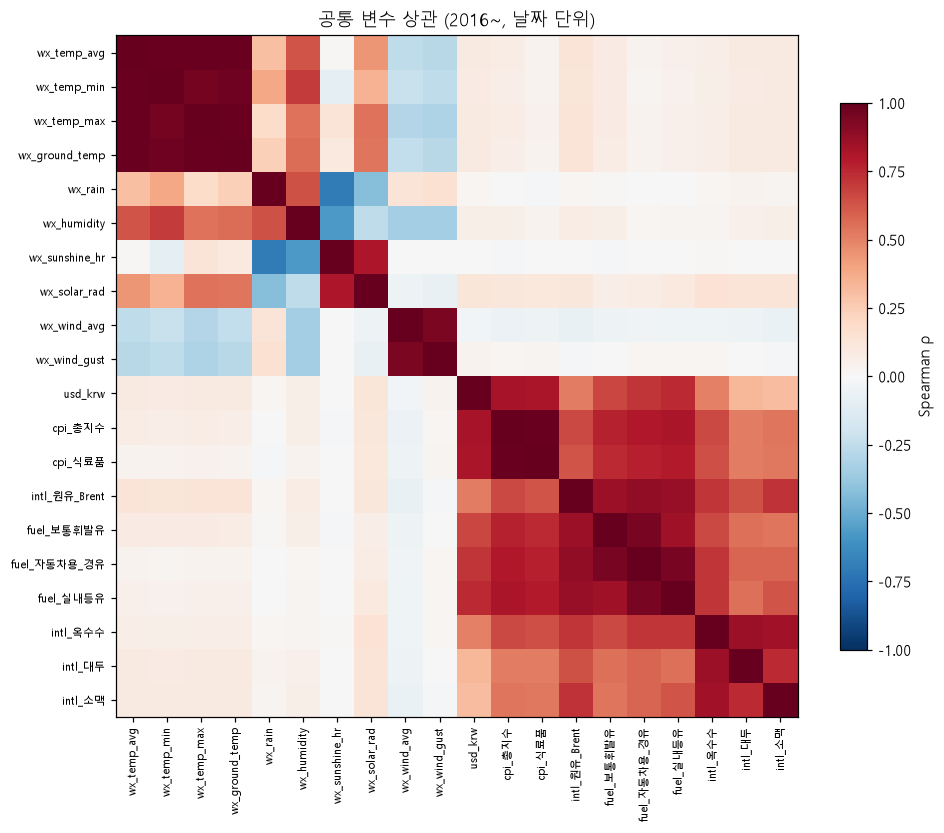

In [3]:
cols = ["wx_temp_avg", "wx_temp_min", "wx_temp_max", "wx_ground_temp", "wx_rain", "wx_humidity", "wx_sunshine_hr", "wx_solar_rad", "wx_wind_avg", "wx_wind_gust",
        "usd_krw", "cpi_총지수", "cpi_식료품", "intl_원유_Brent", "fuel_보통휘발유", "fuel_자동차용_경유", "fuel_실내등유", "intl_옥수수", "intl_대두", "intl_소맥"]
day = ds["agri"].drop_duplicates("date").set_index("date")[cols]
C = day.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(C.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90, fontsize=7); ax.set_yticks(range(len(cols)), cols, fontsize=7)
fig.colorbar(im, shrink=0.8, label="Spearman ρ"); ax.set_title("공통 변수 상관 (2016~, 날짜 단위)"); plt.tight_layout()

In [4]:
# |ρ| ≥ 0.8 쌍 — 같은 역할을 하는 변수 후보
pairs = C.where(np.triu(np.ones(C.shape, bool), 1)).stack()
pairs[pairs.abs() >= 0.8].sort_values(key=abs, ascending=False).rename("ρ").to_frame()

ρ
cpi_총지수        cpi_식료품        0.990
wx_temp_avg    wx_ground_temp 0.989
               wx_temp_min    0.988
wx_temp_max    wx_ground_temp 0.987
wx_temp_avg    wx_temp_max    0.987
wx_temp_min    wx_ground_temp 0.969
               wx_temp_max    0.954
fuel_보통휘발유     fuel_자동차용_경유   0.950
fuel_자동차용_경유   fuel_실내등유      0.947
wx_wind_avg    wx_wind_gust   0.939
intl_원유_Brent  fuel_자동차용_경유   0.889
               fuel_실내등유      0.873
intl_옥수수       intl_대두        0.859
intl_원유_Brent  fuel_보통휘발유     0.855
fuel_보통휘발유     fuel_실내등유      0.849
intl_옥수수       intl_소맥        0.836
usd_krw        cpi_총지수        0.824
cpi_총지수        fuel_실내등유      0.817
usd_krw        cpi_식료품        0.817
wx_sunshine_hr wx_solar_rad   0.808
cpi_총지수        fuel_자동차용_경유   0.802

## 2. 변수와 4주 뒤 가격 변화의 상관 (분야별 상위 15개)

`dataset.parquet` 변수와 `features.parquet`의 4주 변화율 y를 품목·날짜로 맞춰 계산.

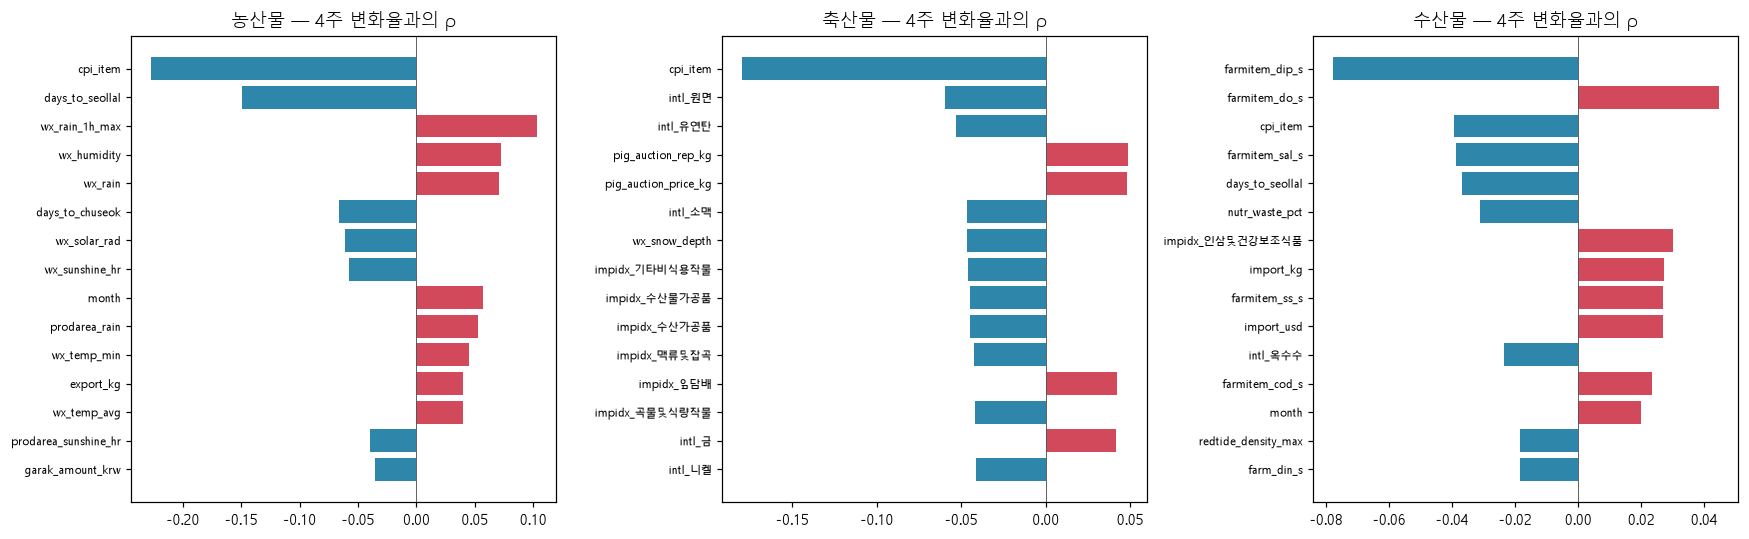

In [5]:
KEYS = ["ctgry_cd", "item_cd", "item_nm", "vrty_nm", "grd_nm", "se_nm", "date"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (d, df) in zip(axes, ds.items()):
    f = pd.read_parquet(P / d / "features.parquet", columns=KEYS + ["y"])
    m = df.merge(f, on=KEYS)
    num = [c for c in m.select_dtypes("number").columns if c not in ("y", "target_mean_14d", "target_mean_28d", "year", "price_kg") and m[c].nunique() > 5]
    rho = m[num].corrwith(m.y, method="spearman").dropna()
    top = rho.reindex(rho.abs().sort_values(ascending=False).index[:15])[::-1]
    ax.barh(top.index, top.values, color=np.where(top.values > 0, "#d1495b", "#2e86ab")); ax.axvline(0, color="#555", lw=0.6)
    ax.tick_params(axis="y", labelsize=7); ax.set_title(f"{NAMES[d]} — 4주 변화율과의 ρ")
plt.tight_layout()

원본 변수 하나와 4주 변화율의 상관은 세 분야 모두 |ρ| 0.23 이하로 작다. 변수 하나로는 가격 변화를 설명하기 어렵고, 가격 이력·여러 변수의 조합이 필요하다.